# YOLOv12n · Skenario Baseline

Notebook ini melatih dan mengevaluasi **YOLOv12 varian Nano** pada skenario **baseline**, yaitu 700 citra siang hari dengan augmentasi 3× dan **tanpa** tambahan citra malam sintetis CycleGAN-Turbo. Notebook ini adalah satu dari 15 konfigurasi pelatihan pada Tabel 4.5 naskah.

| Pengaturan | Nilai |
|---|---|
| Model awal | `yolov12n.pt` (pretrained COCO) |
| Dataset (Kaggle) | `pororozagi/the-basic` |
| Data latih / validasi / uji | 2.100 / 200 / 100 citra |
| Epoch | 50 |
| Ukuran citra | 640 × 640 |
| Batch | 16 |
| Optimizer | SGD (lr0 = 0,01, momentum = 0,937, weight decay = 0,0005) |
| Nama run | `yolov12n_baseline` |

**Hasil pada data uji** (100 citra malam NPD, 166 objek):

| Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|
| 0,7049 | 0,5037 | 0,5744 | 0,2951 |

Seluruh bobot, kurva, dan ringkasan metrik disimpan ke Google Drive pada folder `MyDrive/Output Yolo/Baseline/yolov12n_baseline`.

## 1. Cek GPU

Pelatihan dijalankan pada GPU Tesla T4 di Google Colab. Pastikan runtime sudah diatur ke GPU melalui **Runtime → Change runtime type → T4 GPU**.

In [1]:
!nvidia-smi

Fri Oct 23 07:53:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Kunci versi PyTorch

Versi PyTorch bawaan Colab dapat berubah sewaktu-waktu. Sel berikut memasang torch 2.9.0 agar lingkungan sama dengan seluruh eksperimen. Setelah instalasi, runtime perlu dimulai ulang supaya versi baru termuat.

> Jalankan dua sel di bawah ini **satu kali**. Pesan *"Your session crashed"* setelah sel kedua adalah hal yang wajar. Setelah itu, lanjutkan dari bagian **3. Instal dependensi** (jangan menggunakan *Run all* dari atas).

In [2]:
!pip install -q torch==2.9.0 torchvision==0.24.0 torchaudio==2.9.0 --index-url https://download.pytorch.org/whl/cu128

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 131.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 210.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 180.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 52.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 62.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 99.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 123.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 85.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 86.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 89.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 82.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.7/124.7 MB 90.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# Mulai ulang runtime agar torch 2.9.0 termuat
import os
os.kill(os.getpid(), 9)

## 3. Instal dependensi

YOLOv12 belum tersedia sebagai paket PyPI resmi, sehingga dipasang langsung dari repositori GitHub `sunsmarterjie/yolov12`. Repositori ini merupakan fork Ultralytics 8.3.63. Instalasi dikunci ke commit `3bca22b` agar kode pelatihan, augmentasi bawaan, dan fungsi loss identik dengan yang dipakai pada seluruh eksperimen.

FlashAttention tidak dipasang karena tidak didukung oleh GPU T4. Pada GPU ini, YOLOv12 otomatis memakai *scaled dot-product attention*.

Sel kedua memeriksa versi lingkungan dan akan berhenti dengan pesan kesalahan bila ada versi yang tidak sesuai.

In [1]:
!pip install -q "git+https://github.com/sunsmarterjie/yolov12.git@3bca22b336e96cfdabfec4c062b84eef210e9563"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import sys, torch, ultralytics

print("Python      :", sys.version.split()[0])
print("Torch       :", torch.__version__, "| CUDA:", torch.version.cuda)
print("Ultralytics :", ultralytics.__version__)
print("GPU         :", torch.cuda.get_device_name(0))

assert torch.__version__.startswith("2.9.0"), f"Versi torch tidak sesuai: {torch.__version__}"
assert ultralytics.__version__ == "8.3.63",   f"Versi Ultralytics tidak sesuai: {ultralytics.__version__}"
assert "T4" in torch.cuda.get_device_name(0), f"GPU bukan T4: {torch.cuda.get_device_name(0)}"

print("\nLingkungan sesuai dengan konfigurasi eksperimen.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/yolov12/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
FlashAttention is not available on this device. Using scaled_dot_product_attention instead.
Python      : 3.13.15
Torch       : 2.9.0+cu128 | CUDA: 12.8
Ultralytics : 8.3.63
GPU         : Tesla T4

Lingkungan sesuai dengan konfigurasi eksperimen.


## 4. Konfigurasi eksperimen

Seluruh nama yang berbeda antar-notebook dikumpulkan di sel ini. Sel lain tidak perlu diubah.

In [3]:
MODEL_WEIGHTS = "yolov12n.pt"                    # varian YOLOv12
DATASET_SLUG  = "pororozagi/the-basic"           # skenario data latih (Kaggle)
SCENARIO      = "Baseline (augmentasi 3x, tanpa data sintetis)"
RUN_NAME      = "yolov12n_baseline"              # nama folder hasil pelatihan

EXPORT_PATH   = "/content/dataset"
DATA_YAML     = "/content/data_ready.yaml"

# Lokasi penyimpanan hasil di Google Drive
OUTPUT_GROUP  = "Baseline"                       # Baseline / 50 Sintetis / 100 Sintetis / SOTA
OUTPUT_DIR    = f"/content/drive/MyDrive/notebook YOLO/Output Yolo/{OUTPUT_GROUP}/{RUN_NAME}"

## 5. Unduh dataset dari Kaggle

Dataset diunduh dari Kaggle menggunakan kredensial yang disimpan di **Colab Secrets** (`KAGGLE_USERNAME` dan `KAGGLE_KEY`). Setelah diekstrak, path pada `data.yaml` ditulis ulang menjadi path absolut, lalu jumlah citra dan label pada setiap split diperiksa.

In [4]:
import os
import yaml
from google.colab import userdata

# 1. Kredensial Kaggle dari Colab Secrets
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

# 2. Unduh dan ekstrak dataset
if not os.path.exists(EXPORT_PATH):
    print("⏳ Sedang mendownload dataset...")
    !kaggle datasets download -d {DATASET_SLUG} -p {EXPORT_PATH} --unzip
    print("✅ Download selesai.")
else:
    print("ℹ️ Dataset sudah ada.")

# 3. Cari folder root dataset (yang berisi train dan valid)
actual_base_path = EXPORT_PATH
for root, dirs, files in os.walk(EXPORT_PATH):
    if 'train' in dirs and 'valid' in dirs:
        actual_base_path = root
        break
print(f"📍 Root dataset ditemukan di: {actual_base_path}")

# 4. Tulis ulang data.yaml dengan path absolut
yaml_src = None
for root, dirs, files in os.walk(EXPORT_PATH):
    for f in files:
        if f.endswith('.yaml'):
            yaml_src = os.path.join(root, f)
            break

if yaml_src:
    with open(yaml_src, 'r') as f:
        data = yaml.safe_load(f)

    data['train'] = os.path.join(actual_base_path, 'train', 'images')
    data['val']   = os.path.join(actual_base_path, 'valid', 'images')
    data['test']  = os.path.join(actual_base_path, 'test', 'images')

    with open(DATA_YAML, 'w') as f:
        yaml.dump(data, f)
    print(f"✅ YAML diperbaiki: {DATA_YAML}")
else:
    print("❌ ERROR: File .yaml tidak ditemukan!")

# 5. Periksa jumlah citra dan label pada setiap split
print("\n" + "="*30)
print("📊 LAPORAN DATASET")
print("="*30)

for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(actual_base_path, split, 'images')
    lbl_dir = os.path.join(actual_base_path, split, 'labels')

    if os.path.exists(img_dir) and os.path.exists(lbl_dir):
        n_imgs = len([f for f in os.listdir(img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        n_lbls = len([f for f in os.listdir(lbl_dir) if f.endswith('.txt')])

        status = "✅ MATCH" if n_imgs == n_lbls else "❌ MISMATCH"
        print(f"[{split.upper()}]")
        print(f"  - Gambar: {n_imgs}")
        print(f"  - Label : {n_lbls}")
        print(f"  - Status: {status}")

        if n_imgs == 0:
            print(f"  ⚠️ PERINGATAN: Folder {split} kosong!")
    else:
        print(f"❌ [{split.upper()}] Folder images/labels tidak ditemukan!")

print("="*30)

⏳ Sedang mendownload dataset...
Dataset URL: https://www.kaggle.com/datasets/pororozagi/the-basic
License(s): unknown
100% 217M/217M [00:01<00:00, 123MB/s]

✅ Download selesai.
📍 Root dataset ditemukan di: /content/dataset
✅ YAML diperbaiki: /content/data_ready.yaml

📊 LAPORAN DATASET
[TRAIN]
  - Gambar: 2100
  - Label : 2100
  - Status: ✅ MATCH
[VALID]
  - Gambar: 200
  - Label : 200
  - Status: ✅ MATCH
[TEST]
  - Gambar: 100
  - Label : 100
  - Status: ✅ MATCH


**Insight.** Jumlah citra dan label cocok pada ketiga split.
- **Latih:** 2.100 citra, berasal dari 700 citra siang asli yang masing-masing menghasilkan tiga versi augmentasi.
- **Validasi:** 200 citra (100 siang dan 100 malam).
- **Uji:** 100 citra malam dari NPD.

Data validasi dan data uji sama untuk seluruh skenario, sehingga perbedaan hasil antar-skenario hanya berasal dari data latih.

## 6. Pelatihan model

Model diinisialisasi dari bobot pretrained COCO, lalu di-*fine-tune* selama 50 epoch. Hyperparameter pada sel ini sama untuk seluruh 15 konfigurasi (Tabel 4.4 naskah), sedangkan hyperparameter lain mengikuti nilai bawaan Ultralytics, termasuk `seed=0`. Bobot dengan nilai *fitness* validasi tertinggi disimpan sebagai `best.pt`.

In [5]:
from ultralytics import YOLO
import torch
import os

# 1. Cek perangkat
device_to_use = 0 if torch.cuda.is_available() else 'cpu'
if device_to_use == 'cpu':
    print("⚠️ PERINGATAN: GPU tidak terdeteksi. Training akan sangat lambat!")
else:
    print(f"✅ GPU Terdeteksi: {torch.cuda.get_device_name(0)}")

# 2. Muat bobot pretrained COCO sebagai titik awal fine-tuning
model = YOLO(MODEL_WEIGHTS)

# 3. Pelatihan
assert os.path.exists(DATA_YAML), f"{DATA_YAML} tidak ditemukan. Jalankan sel unduh dataset terlebih dahulu."

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    optimizer='SGD',
    lr0=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    device=device_to_use,
    name=RUN_NAME
)

✅ GPU Terdeteksi: Tesla T4


100%|██████████| 5.26M/5.26M [00:00<00:00, 70.7MB/s]


New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=yolov12n.pt, data=/content/data_ready.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=yolov12n_baseline, exist_ok=False, pretrained=True, optimizer=SGD, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save

100%|██████████| 755k/755k [00:00<00:00, 18.1MB/s]


Overriding model.yaml nc=80 with nc=1

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      2368  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2, 1, 2]          
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1      9344  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2, 1, 4]          
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  2    174720  ultralytics.nn.modules.block.A2C2f           [128, 128, 2, True, 4]        
  7                  -1  1    295424  ultralytics

...

      50/50      3.72G     0.9962     0.6244      1.239          5        640: 100%|██████████| 132/132 [00:44<00:00,  2.98it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:02<00:00,  3.39it/s]

                   all        200        409      0.745      0.615      0.647      0.348



50 epochs completed in 0.696 hours.
Optimizer stripped from runs/detect/yolov12n_baseline/weights/last.pt, 5.4MB
Optimizer stripped from runs/detect/yolov12n_baseline/weights/best.pt, 5.4MB

Validating runs/detect/yolov12n_baseline/weights/best.pt...
Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 376 layers, 2,508,539 parameters, 0 gradients, 5.8 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:04<00:00,  1.57it/s]


                   all        200        409      0.745      0.607      0.654      0.358
Speed: 0.3ms preprocess, 6.6ms inference, 0.0ms loss, 5.3ms postprocess per image
Results saved to runs/detect/yolov12n_baseline


**Insight.**
- Pelatihan 50 epoch selesai dalam **0,673 jam** (sekitar 40 menit) pada GPU T4.
- Bobot terbaik dicapai pada **epoch 47**, dengan hasil validasi Precision 0,745, Recall 0,607, mAP@0.5 **0,654**, dan mAP@0.5:0.95 **0,358**.
- Kecepatan inferensi pada data validasi sekitar 4,9 ms per citra.

## 7. Kurva pelatihan dan validasi

In [6]:
import os
import glob
import matplotlib.pyplot as plt
import cv2

results_dir = f'runs/detect/{RUN_NAME}'
if not os.path.exists(results_dir):
    # Gunakan folder run terbaru bila nama di atas tidak ditemukan
    results_dir = max(glob.glob('runs/detect/*'), key=os.path.getmtime)

print(f"📂 Mengambil hasil dari: {results_dir}")

📂 Mengambil hasil dari: runs/detect/yolov12n_baseline


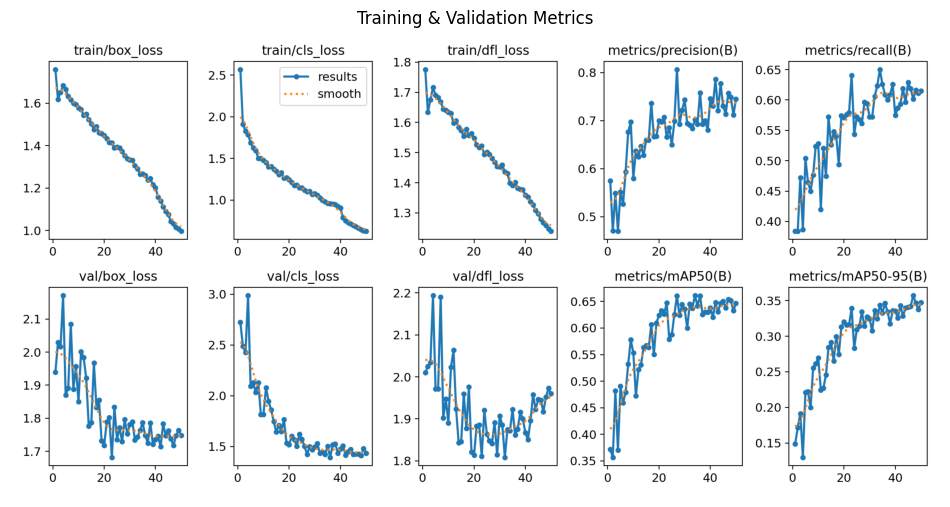

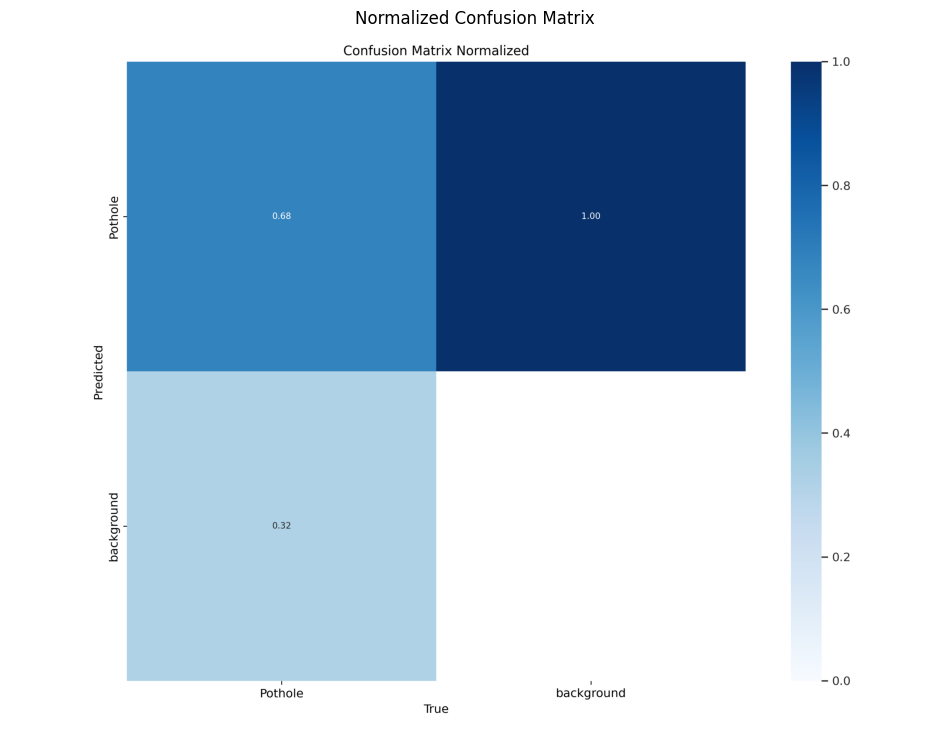

In [7]:
def show_image(path, title):
    if os.path.exists(path):
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(12, 10))
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ File {path} tidak ditemukan.")

# Grafik loss dan metrik per epoch
show_image(f"{results_dir}/results.png", "Training & Validation Metrics")

# Confusion matrix ternormalisasi pada data validasi
show_image(f"{results_dir}/confusion_matrix_normalized.png", "Normalized Confusion Matrix")

**Insight.**
- **Loss latih:** ketiga komponen loss latih (box, cls, dfl) turun secara konsisten selama 50 epoch. Penurunan tampak lebih tajam setelah epoch 40, ketika augmentasi mosaic dimatikan untuk 10 epoch terakhir (`close_mosaic=10`, nilai bawaan).
- **Loss validasi:** box loss dan cls loss validasi menurun sampai sekitar epoch 20, lalu relatif datar. DFL loss validasi mencapai nilai terendah di sekitar epoch 20 sampai 30, lalu sedikit naik menjelang akhir pelatihan.
- **mAP validasi:** naik cepat pada 20 epoch pertama, lalu stabil di kisaran 0,62 sampai 0,66.

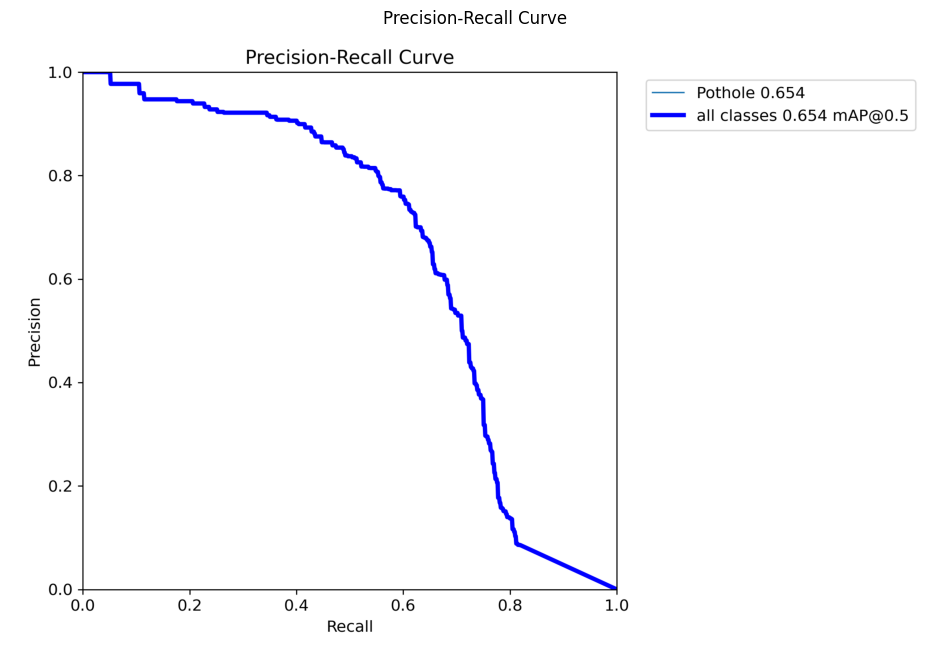

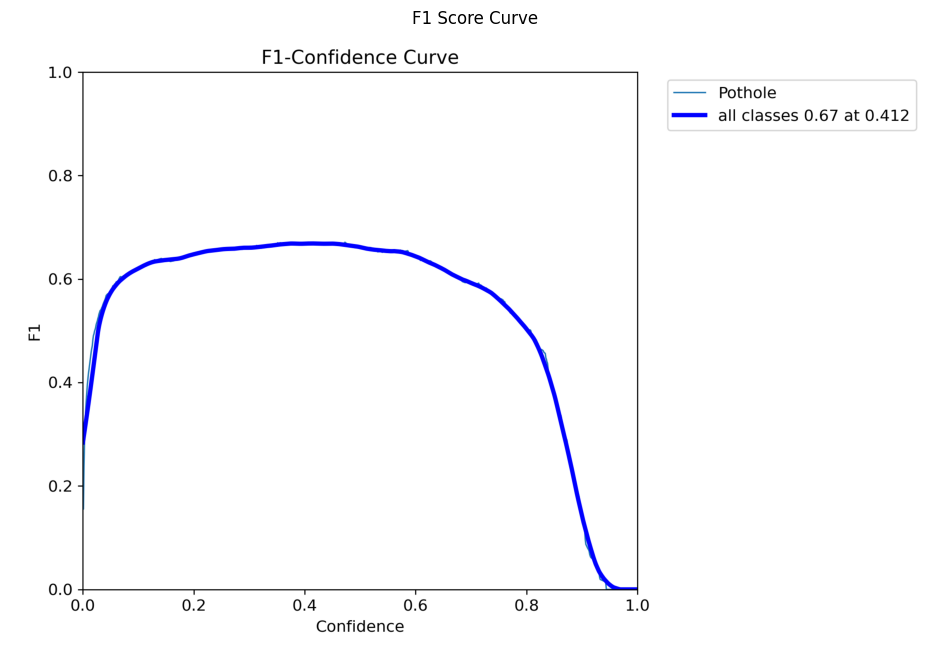

In [8]:
# Kurva Precision-Recall dan F1-confidence pada data validasi
show_image(f"{results_dir}/PR_curve.png", "Precision-Recall Curve")
show_image(f"{results_dir}/F1_curve.png", "F1 Score Curve")

**Insight.**
- **Kurva PR (data validasi):** luas di bawah kurva adalah 0,654. Precision bertahan di atas 0,9 sampai recall sekitar 0,4, lalu menurun tajam setelah recall melewati 0,65.
- **Kurva F1:** F1 maksimum sebesar **0,67** dicapai pada confidence **0,376**. Precision dan Recall yang dilaporkan Ultralytics untuk model ini diambil pada titik tersebut.

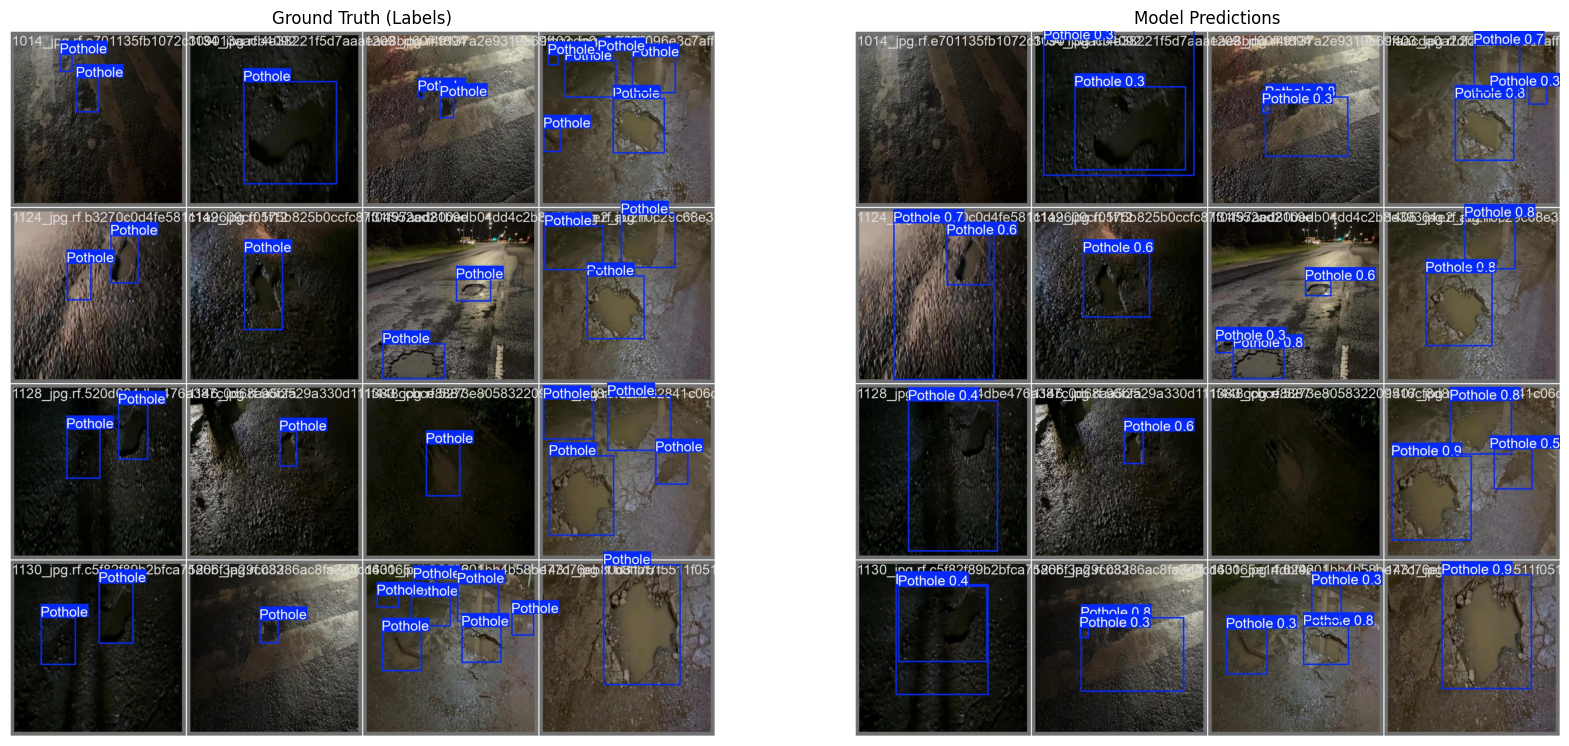

In [9]:
# Perbandingan label asli dan prediksi pada batch pertama data validasi
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

img_labels = cv2.imread(f"{results_dir}/val_batch0_labels.jpg")
axes[0].imshow(cv2.cvtColor(img_labels, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ground Truth (Labels)")
axes[0].axis('off')

img_pred = cv2.imread(f"{results_dir}/val_batch0_pred.jpg")
axes[1].imshow(cv2.cvtColor(img_pred, cv2.COLOR_BGR2RGB))
axes[1].set_title("Model Predictions")
axes[1].axis('off')

plt.show()

### Kurva per epoch dari `results.csv`

Grafik bawaan Ultralytics digambar ulang dari `results.csv` agar loss latih dan loss validasi berada pada satu panel untuk setiap komponen, serta epoch terbaik ditandai secara eksplisit. Epoch terbaik ditentukan dengan nilai *fitness* yang sama dengan Ultralytics, yaitu 0,1 × mAP@0.5 + 0,9 × mAP@0.5:0.95.

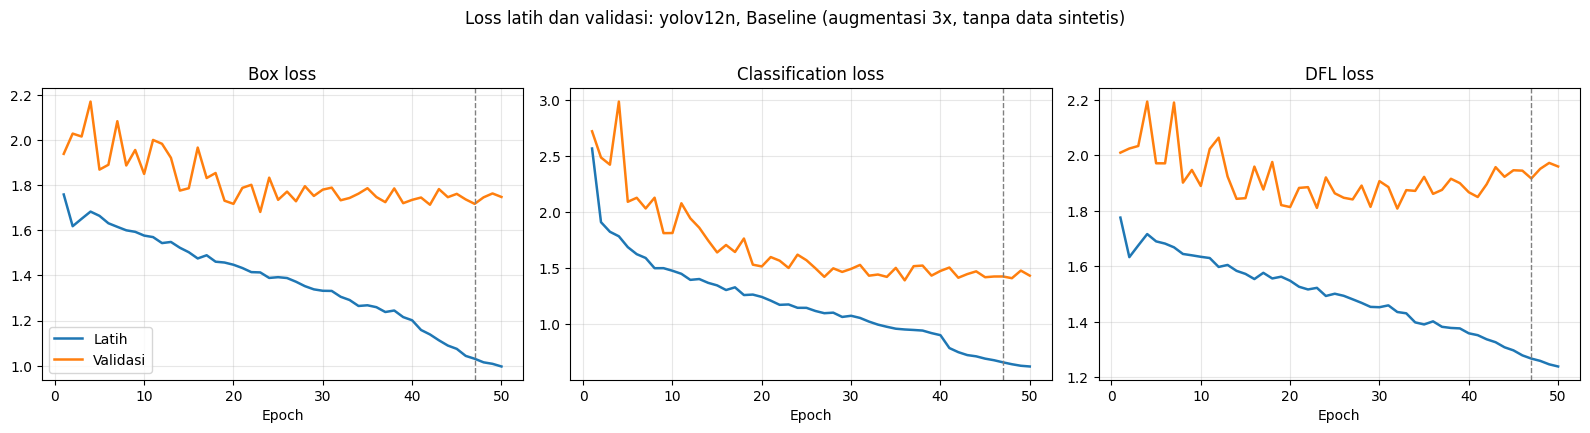

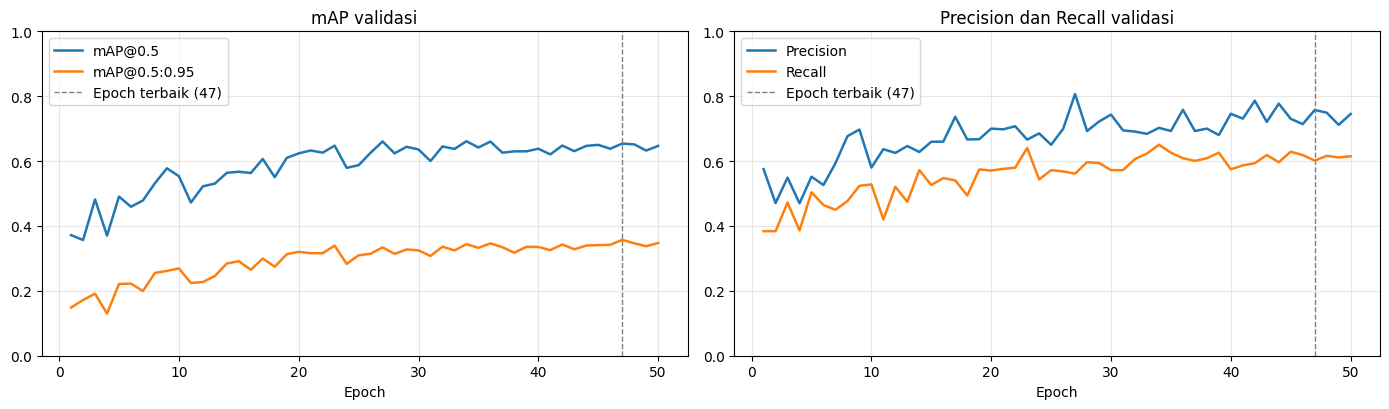

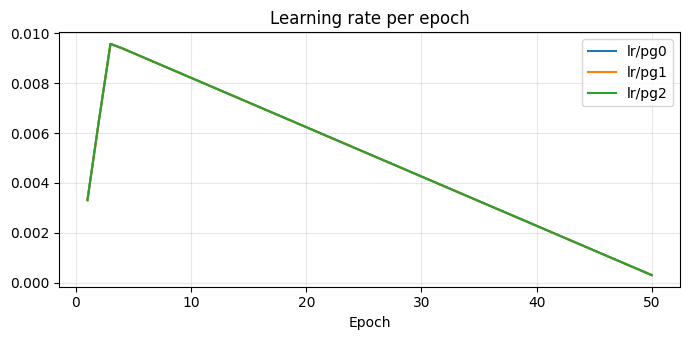

Epoch terbaik: 47
metrics/precision(B)    0.7574
metrics/recall(B)       0.6015
metrics/mAP50(B)        0.6539
metrics/mAP50-95(B)     0.3572


In [10]:
import pandas as pd

hist = pd.read_csv(f"{results_dir}/results.csv")
hist.columns = hist.columns.str.strip()
epochs = hist["epoch"]

fitness = 0.1 * hist["metrics/mAP50(B)"] + 0.9 * hist["metrics/mAP50-95(B)"]
best_idx = int(fitness.idxmax())
best_epoch = int(epochs[best_idx])

# Loss latih vs validasi
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, comp, title in zip(axes, ["box", "cls", "dfl"], ["Box loss", "Classification loss", "DFL loss"]):
    ax.plot(epochs, hist[f"train/{comp}_loss"], label="Latih", lw=1.8)
    ax.plot(epochs, hist[f"val/{comp}_loss"], label="Validasi", lw=1.8)
    ax.axvline(best_epoch, color="grey", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle(f"Loss latih dan validasi: {MODEL_WEIGHTS.replace('.pt', '')}, {SCENARIO}", y=1.02)
plt.tight_layout(); plt.show()

# Metrik validasi per epoch
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(epochs, hist["metrics/mAP50(B)"], label="mAP@0.5", lw=1.8)
axes[0].plot(epochs, hist["metrics/mAP50-95(B)"], label="mAP@0.5:0.95", lw=1.8)
axes[1].plot(epochs, hist["metrics/precision(B)"], label="Precision", lw=1.8)
axes[1].plot(epochs, hist["metrics/recall(B)"], label="Recall", lw=1.8)
for ax, title in zip(axes, ["mAP validasi", "Precision dan Recall validasi"]):
    ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"Epoch terbaik ({best_epoch})")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# Learning rate
lr_cols = [c for c in hist.columns if c.startswith("lr/")]
plt.figure(figsize=(7, 3.5))
for c in lr_cols:
    plt.plot(epochs, hist[c], label=c)
plt.title("Learning rate per epoch"); plt.xlabel("Epoch"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

print(f"Epoch terbaik: {best_epoch}")
print(hist.loc[best_idx, ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].round(4).to_string())

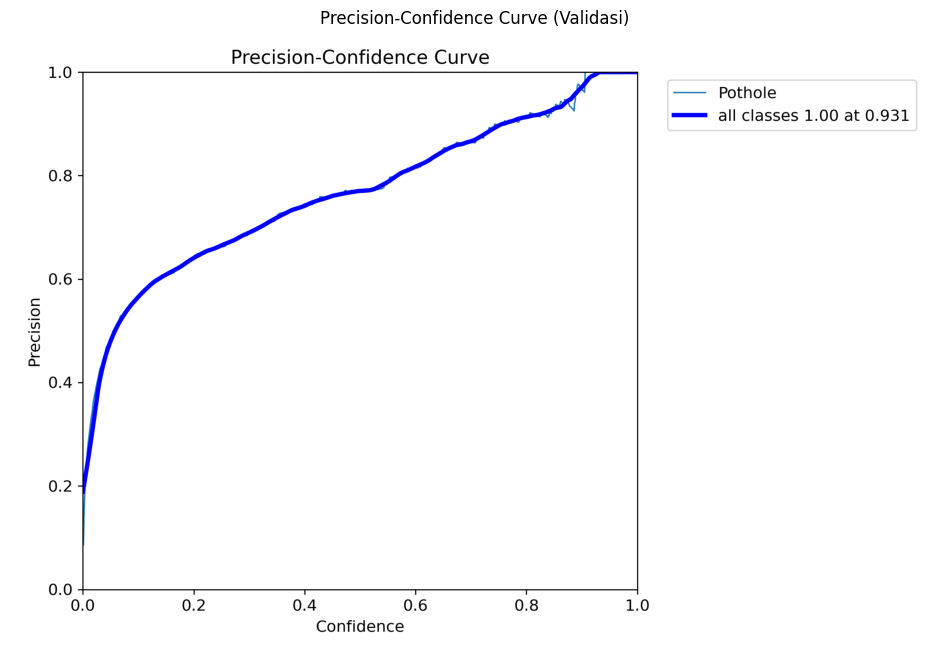

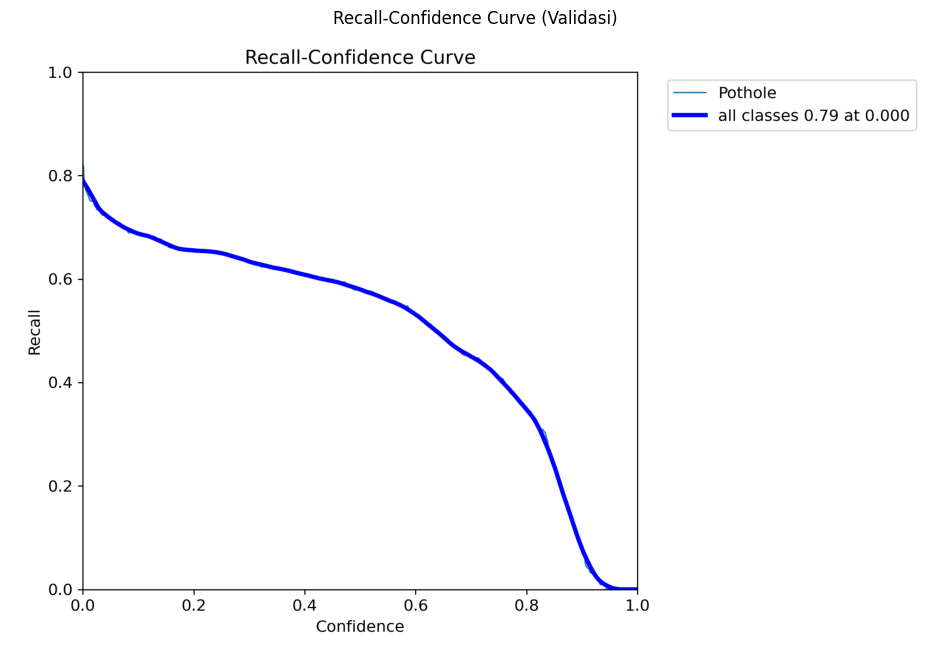

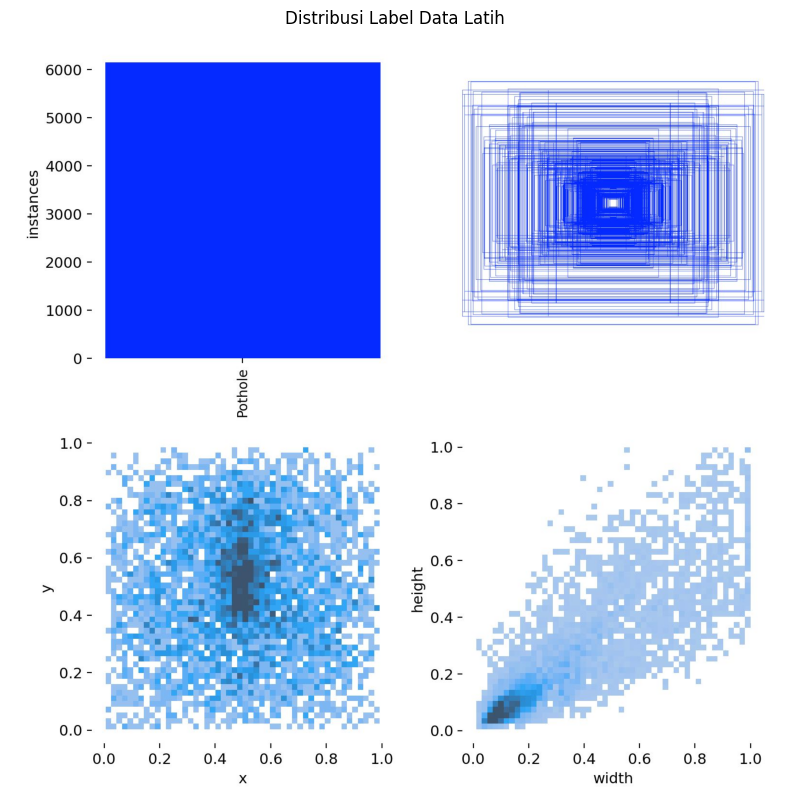

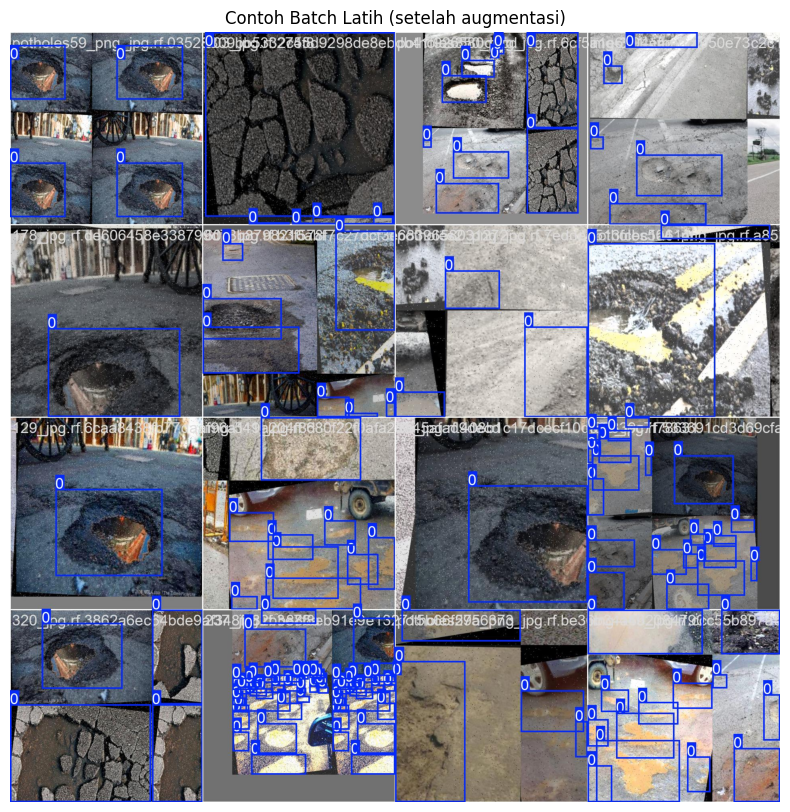

In [11]:
# Kurva Precision-confidence dan Recall-confidence pada data validasi
show_image(f"{results_dir}/P_curve.png", "Precision-Confidence Curve (Validasi)")
show_image(f"{results_dir}/R_curve.png", "Recall-Confidence Curve (Validasi)")

# Distribusi label pada data latih dan contoh batch latih setelah augmentasi
show_image(f"{results_dir}/labels.jpg", "Distribusi Label Data Latih")
show_image(f"{results_dir}/train_batch0.jpg", "Contoh Batch Latih (setelah augmentasi)")

## 8. Evaluasi pada data uji

Bobot terbaik (`best.pt`) dievaluasi pada split uji (100 citra malam NPD) dengan `split='test'`, `imgsz=640`, dan `batch=16`. mAP dihitung pada seluruh rentang confidence, sedangkan Precision dan Recall dilaporkan pada confidence yang menghasilkan F1 maksimum.

In [12]:
from ultralytics import YOLO
import os

best_model_path = f'runs/detect/{RUN_NAME}/weights/best.pt'
model = YOLO(best_model_path)

metrics = model.val(
    data=DATA_YAML,
    split='test',
    imgsz=640,
    batch=16,
    name=f'eval_test_{RUN_NAME}'
)

def get_metric(metrics_dict, keys):
    # Nama key berbeda antarversi Ultralytics
    for key in keys:
        if key in metrics_dict:
            return metrics_dict[key]
    return 0.0

res = metrics.results_dict
map50 = get_metric(res, ['metrics/map50', 'metrics/mAP50(B)'])
map95 = get_metric(res, ['metrics/map50-95', 'metrics/mAP50-95(B)'])
prec  = get_metric(res, ['metrics/precision', 'metrics/precision(B)'])
rec   = get_metric(res, ['metrics/recall', 'metrics/recall(B)'])

print("\n" + "="*30)
print("📈 HASIL EVALUASI DATA TEST")
print("="*30)
print(f"mAP50:       {map50:.4f}")
print(f"mAP50-95:    {map95:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"Recall:      {rec:.4f}")
print("="*30)

Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 376 layers, 2,508,539 parameters, 0 gradients, 5.8 GFLOPs


val: Scanning /content/dataset/test/labels... 100 images, 0 backgrounds, 0 corrupt: 100%|██████████| 100/100 [00:00<00:00, 1835.29it/s]

val: New cache created: /content/dataset/test/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:03<00:00,  2.21it/s]


                   all        100        166      0.705      0.504      0.574      0.295
Speed: 0.4ms preprocess, 11.7ms inference, 0.0ms loss, 6.4ms postprocess per image
Results saved to runs/detect/eval_test_yolov12n_baseline

📈 HASIL EVALUASI DATA TEST
mAP50:       0.5744
mAP50-95:    0.2951
Precision:   0.7049
Recall:      0.5037


**Insight.**
- **Hasil uji:** Precision **0,7049**, Recall **0,5037**, mAP@0.5 **0,5744**, dan mAP@0.5:0.95 **0,2951**. Angka ini menjadi baris baseline YOLOv12n pada Tabel 4.7 naskah.
- **Perbandingan dengan validasi:** mAP@0.5 pada data uji lebih rendah daripada pada data validasi (0,654). Perbedaan ini sejalan dengan komposisi datanya: data validasi berisi citra siang dan malam, sedangkan data uji seluruhnya citra malam.
- **Kecepatan:** waktu inferensi pada data uji sekitar 14,9 ms per citra.


0: 640x640 3 Potholes, 21.1ms
1: 640x640 1 Pothole, 21.1ms
2: 640x640 1 Pothole, 21.1ms
Speed: 1.9ms preprocess, 21.1ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)


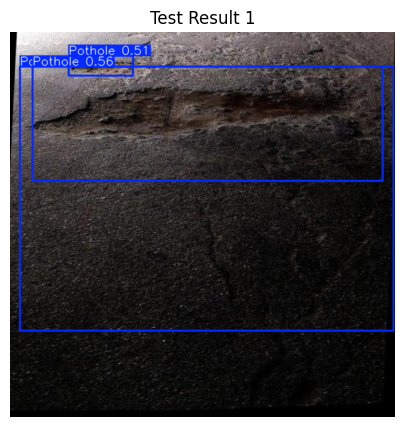

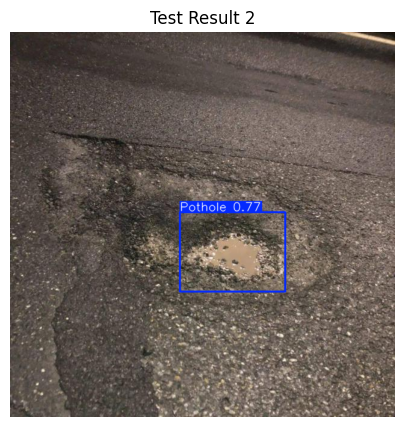

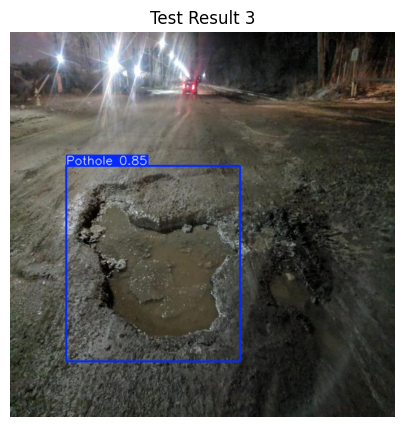

In [13]:
import glob
import yaml

# Contoh prediksi pada tiga citra pertama data uji (confidence 0,25)
with open(DATA_YAML, 'r') as f:
    config = yaml.safe_load(f)
test_files = glob.glob(os.path.join(config['test'], "*.jpg"))[:3]

results = model.predict(source=test_files, conf=0.25)

for i, r in enumerate(results):
    img_rgb = cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.title(f"Test Result {i+1}")
    plt.axis('off')
    plt.show()

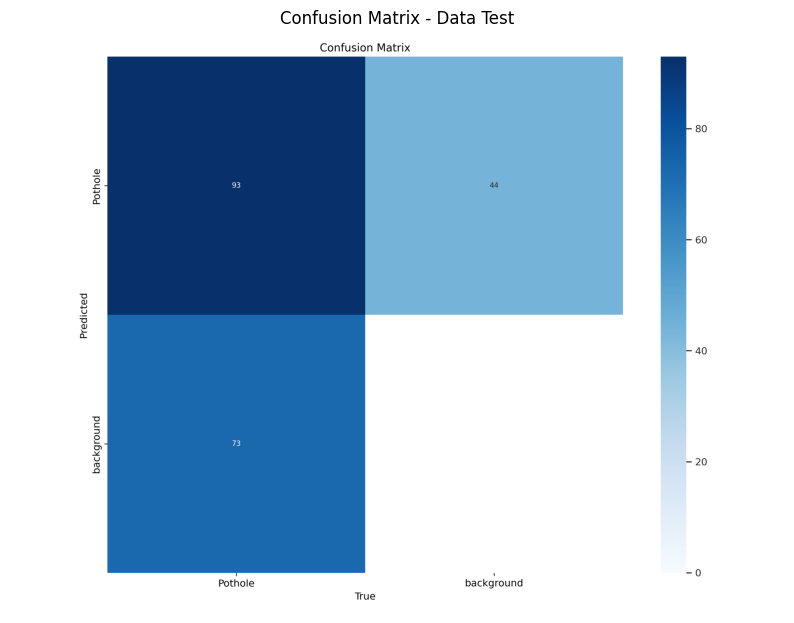

In [14]:
eval_test_dir = f'runs/detect/eval_test_{RUN_NAME}'

def show_eval_plot(directory, filename, title):
    path = os.path.join(directory, filename)
    if os.path.exists(path):
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ File {filename} tidak ditemukan di {directory}. Pastikan model.val() sudah selesai.")

# Confusion matrix pada data uji
show_eval_plot(eval_test_dir, 'confusion_matrix.png', "Confusion Matrix - Data Test")

**Insight.** Confusion matrix dihitung pada ambang bawaan Ultralytics untuk plot ini (confidence 0,25). Dari 166 lubang pada data uji:
- **93** terdeteksi dengan benar (TP),
- **73** terlewat (FN),
- dan terdapat **44** deteksi palsu (FP).

Jumlah lubang yang terlewat lebih besar daripada deteksi palsu. Pola ini sejalan dengan Recall (0,50) yang lebih rendah daripada Precision (0,70).

In [15]:
# Perbandingan label asli dan prediksi pada batch pertama data uji
# (Ultralytics tetap menamai file 'val_batch' walaupun split='test')
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

gt_path = os.path.join(eval_test_dir, 'val_batch0_labels.jpg')
if os.path.exists(gt_path):
    axes[0].imshow(cv2.cvtColor(cv2.imread(gt_path), cv2.COLOR_BGR2RGB))
    axes[0].set_title("Ground Truth (Data Test Labels)", fontsize=15)
    axes[0].axis('off')
else:
    print("⚠️ File label batch tidak ditemukan.")

pred_path = os.path.join(eval_test_dir, 'val_batch0_pred.jpg')
if os.path.exists(pred_path):
    axes[1].imshow(cv2.cvtColor(cv2.imread(pred_path), cv2.COLOR_BGR2RGB))
    axes[1].set_title("Model Predictions (Data Test)", fontsize=15)
    axes[1].axis('off')
else:
    print("⚠️ File prediksi batch tidak ditemukan.")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

### Kurva pada data uji

Kurva PR, F1, Precision, dan Recall terhadap confidence pada data uji, serta confusion matrix ternormalisasi.

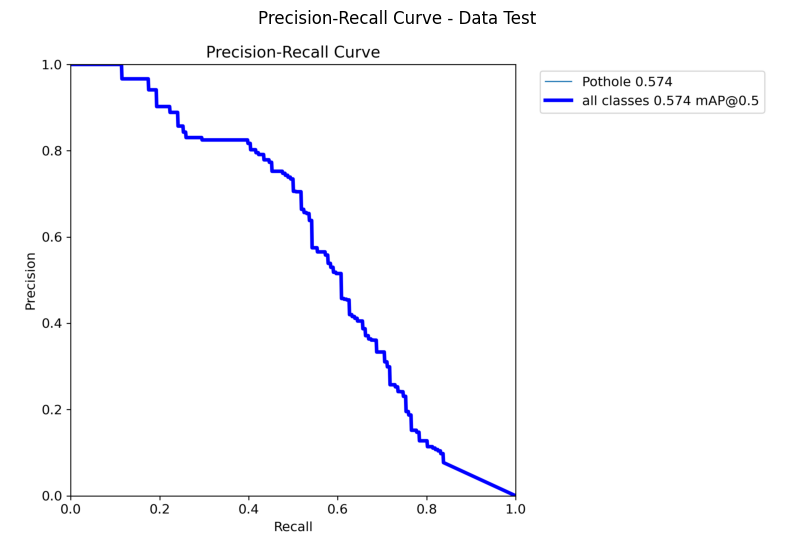

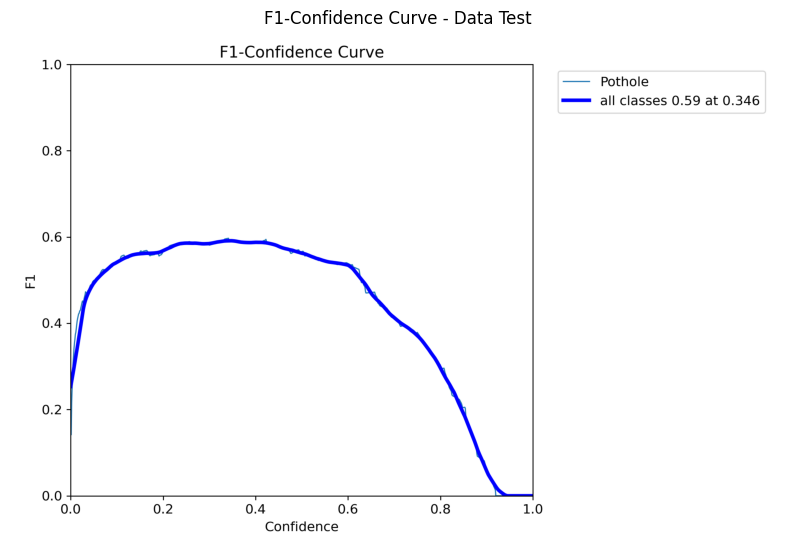

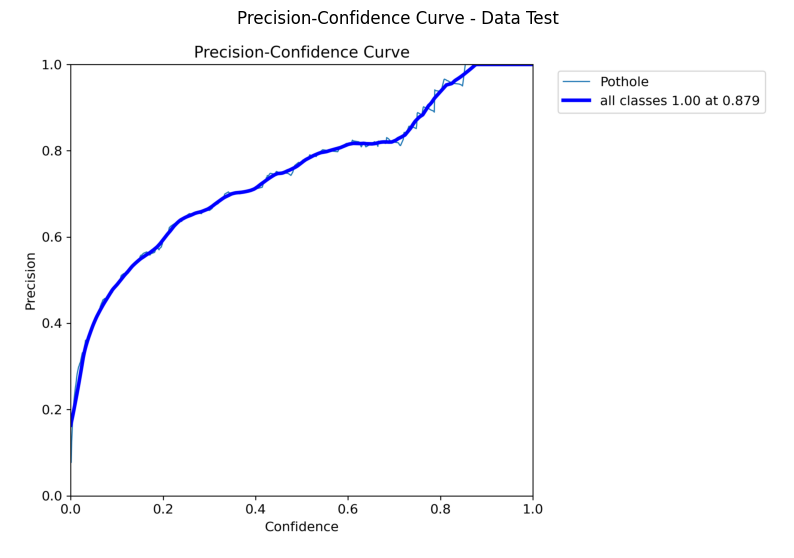

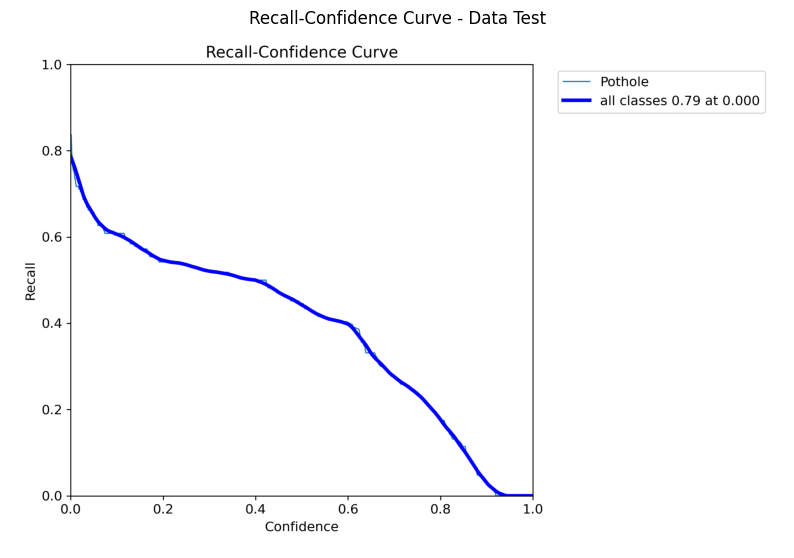

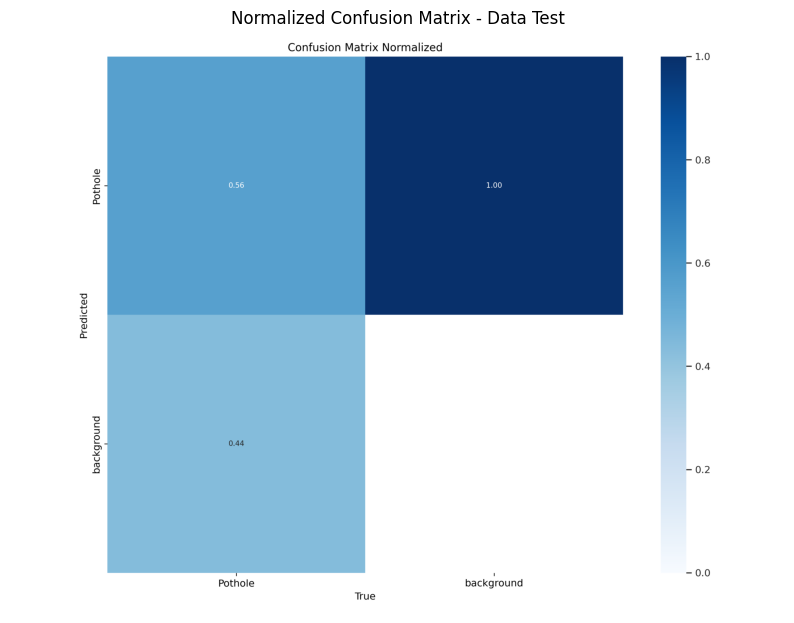

In [16]:
show_eval_plot(eval_test_dir, 'PR_curve.png', "Precision-Recall Curve - Data Test")
show_eval_plot(eval_test_dir, 'F1_curve.png', "F1-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'P_curve.png', "Precision-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'R_curve.png', "Recall-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'confusion_matrix_normalized.png', "Normalized Confusion Matrix - Data Test")

## 9. Ringkasan dan penyimpanan ke Google Drive

Sel pertama menyusun ringkasan metrik uji, jumlah parameter, kecepatan inferensi, dan versi lingkungan. Sel kedua menyimpan seluruh hasil ke Google Drive:

```
MyDrive/Output Yolo/<OUTPUT_GROUP>/<RUN_NAME>/
├── train/                  # folder hasil pelatihan (weights/best.pt, results.csv, kurva)
├── eval_test/              # folder hasil evaluasi pada data uji
└── summary_<RUN_NAME>.json # ringkasan metrik dan lingkungan
```

In [17]:
import json, sys
import torch, ultralytics

n_params = sum(p.numel() for p in model.model.parameters())
inf_ms = metrics.speed.get('inference', float('nan'))

summary = {
    "run": RUN_NAME,
    "model": MODEL_WEIGHTS.replace(".pt", ""),
    "scenario": SCENARIO,
    "dataset": DATASET_SLUG,
    "best_epoch": best_epoch,
    "params": int(n_params),
    "inference_ms_per_image": round(float(inf_ms), 2),
    "test": {
        "precision": round(float(prec), 4),
        "recall": round(float(rec), 4),
        "map50": round(float(map50), 4),
        "map50_95": round(float(map95), 4),
    },
    "environment": {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "ultralytics": ultralytics.__version__,
        "gpu": torch.cuda.get_device_name(0),
    },
}
print(json.dumps(summary, indent=2))

{
  "run": "yolov12n_baseline",
  "model": "yolov12n",
  "scenario": "Baseline (augmentasi 3x, tanpa data sintetis)",
  "dataset": "pororozagi/the-basic",
  "best_epoch": 47,
  "params": 2508539,
  "inference_ms_per_image": 11.66,
  "test": {
    "precision": 0.7049,
    "recall": 0.5037,
    "map50": 0.5744,
    "map50_95": 0.2951
  },
  "environment": {
    "python": "3.13.15",
    "torch": "2.9.0+cu128",
    "cuda": "12.8",
    "ultralytics": "8.3.63",
    "gpu": "Tesla T4"
  }
}


In [18]:
import shutil
from google.colab import drive

drive.mount('/content/drive')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Folder hasil pelatihan (berisi weights/best.pt dan last.pt)
shutil.copytree(f'runs/detect/{RUN_NAME}', os.path.join(OUTPUT_DIR, 'train'), dirs_exist_ok=True)

# 2. Folder hasil evaluasi data uji
shutil.copytree(eval_test_dir, os.path.join(OUTPUT_DIR, 'eval_test'), dirs_exist_ok=True)

# 3. Ringkasan metrik
with open(os.path.join(OUTPUT_DIR, f'summary_{RUN_NAME}.json'), 'w') as f:
    json.dump(summary, f, indent=2)

print(f"✅ Hasil tersimpan di: {OUTPUT_DIR}")
for root, dirs, files_ in os.walk(OUTPUT_DIR):
    depth = root[len(OUTPUT_DIR):].count(os.sep)
    if depth <= 1:
        print("  " * depth + os.path.basename(root) + "/")

Mounted at /content/drive
✅ Hasil tersimpan di: /content/drive/MyDrive/notebook YOLO/Output Yolo/Baseline/yolov12n_baseline
yolov12n_baseline/
  train/
  eval_test/
